In [1]:
import os
import sys
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from PIL import Image

In [2]:
model_path = "../saved_models/best_resnet50.keras"

resnet_model = tf.keras.models.load_model(model_path)

print("ResNet50 model loaded successfully!")
print("Model name:", resnet_model.name)
print("Input shape:", resnet_model.input_shape)
print("Output shape:", resnet_model.output_shape)

ResNet50 model loaded successfully!
Model name: ResNet50_DR_Classifier
Input shape: (None, 224, 224, 3)
Output shape: (None, 5)


In [3]:
for layer in resnet_model.layers:
    print(layer.name, layer.output.shape)

retinal_image (None, 224, 224, 3)
resnet50 (None, 7, 7, 2048)
global_average_pooling (None, 2048)
dropout (None, 2048)
dr_severity (None, 5)


In [4]:
conv_layers = []

for layer in resnet_model.layers:
    if len(layer.output.shape) == 4:
        conv_layers.append(layer)

print("Number of 4D layers:", len(conv_layers))

print("\nLast 10 convolutional/feature-map layers:")
for layer in conv_layers[-10:]:
    print(layer.name, layer.output.shape)

Number of 4D layers: 2

Last 10 convolutional/feature-map layers:
retinal_image (None, 224, 224, 3)
resnet50 (None, 7, 7, 2048)


In [5]:
print("\nLast 10 convolutional/feature-map layers:")
for layer in conv_layers[-10:]:
    print(layer.name, layer.output.shape)


Last 10 convolutional/feature-map layers:
retinal_image (None, 224, 224, 3)
resnet50 (None, 7, 7, 2048)


In [6]:
# Find the ResNet50 feature extraction layer
resnet_layer = resnet_model.get_layer("resnet50")

print("Layer name:", resnet_layer.name)
print("Layer output shape:", resnet_layer.output.shape)

Layer name: resnet50
Layer output shape: (None, 7, 7, 2048)


In [10]:
# Get the nested ResNet50 backbone
base_model = resnet_model.get_layer("resnet50")

print("Backbone:", base_model.name)
print("Backbone input:", base_model.input.shape)
print("Backbone output:", base_model.output.shape)

Backbone: resnet50
Backbone input: (None, 224, 224, 3)
Backbone output: (None, 7, 7, 2048)


In [11]:
for layer in base_model.layers[-15:]:
    print(layer.name, layer.output.shape)

conv5_block2_2_relu (None, 7, 7, 512)
conv5_block2_3_conv (None, 7, 7, 2048)
conv5_block2_3_bn (None, 7, 7, 2048)
conv5_block2_add (None, 7, 7, 2048)
conv5_block2_out (None, 7, 7, 2048)
conv5_block3_1_conv (None, 7, 7, 512)
conv5_block3_1_bn (None, 7, 7, 512)
conv5_block3_1_relu (None, 7, 7, 512)
conv5_block3_2_conv (None, 7, 7, 512)
conv5_block3_2_bn (None, 7, 7, 512)
conv5_block3_2_relu (None, 7, 7, 512)
conv5_block3_3_conv (None, 7, 7, 2048)
conv5_block3_3_bn (None, 7, 7, 2048)
conv5_block3_add (None, 7, 7, 2048)
conv5_block3_out (None, 7, 7, 2048)


In [12]:
last_conv_layer = base_model.get_layer("conv5_block3_out")

print("Last convolutional layer:", last_conv_layer.name)
print("Output shape:", last_conv_layer.output.shape)

Last convolutional layer: conv5_block3_out
Output shape: (None, 7, 7, 2048)


In [13]:
feature_model = tf.keras.models.Model(
    inputs=base_model.input,
    outputs=last_conv_layer.output
)

print("Feature model created successfully!")
print("Output shape:", feature_model.output_shape)

Feature model created successfully!
Output shape: (None, 7, 7, 2048)


In [14]:
gap_layer = resnet_model.get_layer("global_average_pooling")
dropout_layer = resnet_model.get_layer("dropout")
classifier_layer = resnet_model.get_layer("dr_severity")

print("GAP layer:", gap_layer.name)
print("Dropout layer:", dropout_layer.name)
print("Classifier:", classifier_layer.name)

GAP layer: global_average_pooling
Dropout layer: dropout
Classifier: dr_severity


In [15]:
def make_gradcam_heatmap(img_array, target_class=None):

    # Watch the feature maps produced by the final
    # convolutional layer
    with tf.GradientTape() as tape:

        # Get final convolutional feature maps
        feature_maps = feature_model(img_array, training=False)

        # Pass feature maps through the classification head
        x = gap_layer(feature_maps)
        x = dropout_layer(x, training=False)
        predictions = classifier_layer(x)

        # If target class is not provided,
        # use the model's predicted class
        if target_class is None:
            target_class = tf.argmax(predictions[0])

        # Probability/logit for selected class
        class_output = predictions[:, target_class]

    # Calculate gradients of selected class
    # with respect to feature maps
    gradients = tape.gradient(
        class_output,
        feature_maps
    )

    # Average gradients across height and width
    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(1, 2)
    )

    # Remove batch dimension
    feature_maps = feature_maps[0]
    pooled_gradients = pooled_gradients[0]

    # Weight feature maps by their importance
    weighted_feature_maps = (
        feature_maps * pooled_gradients
    )

    # Sum across channels
    heatmap = tf.reduce_sum(
        weighted_feature_maps,
        axis=-1
    )

    # Apply ReLU
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize between 0 and 1
    max_value = tf.reduce_max(heatmap)

    if max_value != 0:
        heatmap /= max_value

    return heatmap.numpy(), predictions.numpy()

In [16]:
print("Grad-CAM function updated successfully!")

Grad-CAM function updated successfully!


In [19]:
import sys
import os

# Add preprocessing directory to Python path
project_root = os.path.abspath("D:\AI-Powered-Diabetic-Retinopathy-System\ml-model\notebooks\02_image_preprocessing.ipynb")
preprocessing_dir = os.path.join(project_root, "ml-model", "preprocessing")

if preprocessing_dir not in sys.path:
    sys.path.insert(0, preprocessing_dir)

import dataset_loader

In [20]:
csv_path = r"D:\AI-Powered-Diabetic-Retinopathy-System\ml-model\dataset\raw\train.csv"

image_dir = r"D:\AI-Powered-Diabetic-Retinopathy-System\ml-model\dataset\raw\train_images"

df = dataset_loader.load_metadata(csv_path)

df = dataset_loader.create_image_paths(
    df,
    image_dir
)

df = dataset_loader.validate_image_paths(df)

print("Total images:", len(df))

Total images: 3662


In [21]:
train_df, validation_df, test_df = dataset_loader.split_dataset(
    df,
    test_size=0.15,
    validation_size=0.15,
    random_state=42
)

print("Train images:", len(train_df))
print("Validation images:", len(validation_df))
print("Test images:", len(test_df))

Train images: 2563
Validation images: 549
Test images: 550


In [22]:
sample_row = test_df.iloc[0]

sample_image_path = sample_row["image_path"]
true_label = sample_row["diagnosis"]

print("Image path:", sample_image_path)
print("True class:", true_label)

Image path: D:\AI-Powered-Diabetic-Retinopathy-System\ml-model\dataset\raw\train_images\89ee1fa16f90.png
True class: 2


In [23]:
image = tf.io.read_file(sample_image_path)

image = tf.image.decode_png(
    image,
    channels=3
)

image = tf.image.resize(
    image,
    (224, 224)
)

image = tf.cast(
    image,
    tf.float32
)

# Add batch dimension
img_array = tf.expand_dims(
    image,
    axis=0
)

print("Image tensor shape:", img_array.shape)
print("Minimum pixel value:", tf.reduce_min(img_array).numpy())
print("Maximum pixel value:", tf.reduce_max(img_array).numpy())

Image tensor shape: (1, 224, 224, 3)
Minimum pixel value: 0.0
Maximum pixel value: 255.0


In [24]:
predictions = resnet_model.predict(
    img_array,
    verbose=0
)

predicted_class = np.argmax(
    predictions[0]
)

confidence = predictions[0][predicted_class]

class_names = [
    "No DR",
    "Mild DR",
    "Moderate DR",
    "Severe DR",
    "Proliferative DR"
]

print("True class:")
print(class_names[true_label])

print("\nPredicted class:")
print(class_names[predicted_class])

print("\nConfidence:")
print(f"{confidence * 100:.2f}%")

True class:
Moderate DR

Predicted class:
Moderate DR

Confidence:
43.57%


In [25]:
heatmap, gradcam_predictions = make_gradcam_heatmap(
    img_array,
    target_class=predicted_class
)

print("Heatmap shape:", heatmap.shape)

Heatmap shape: (7, 7)


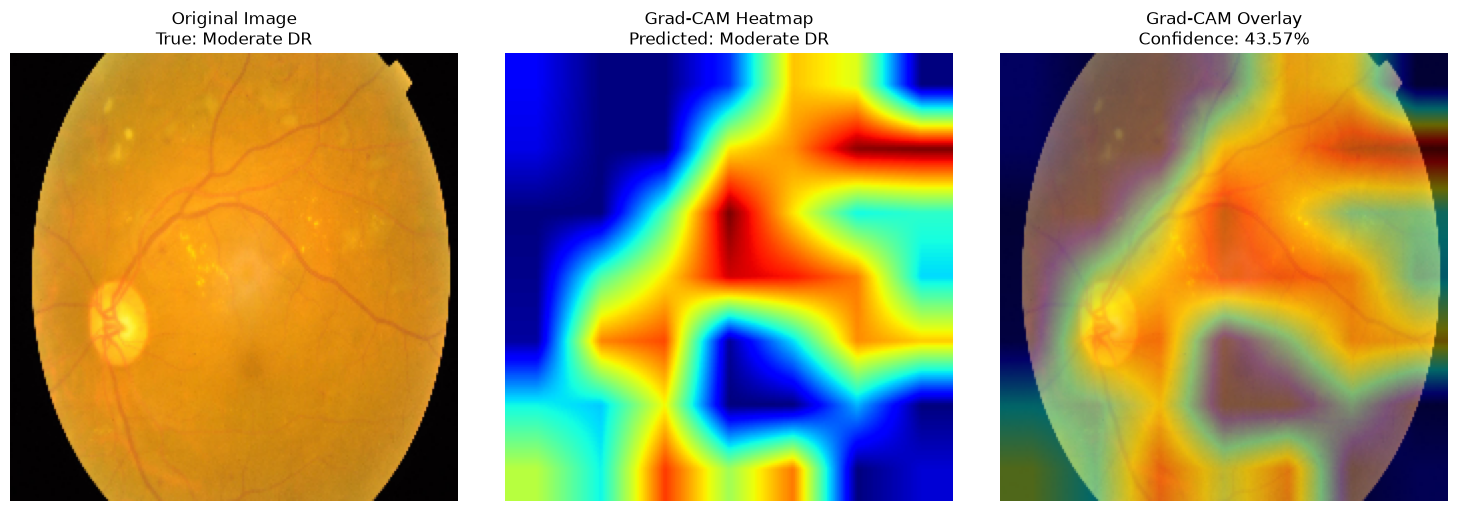

In [26]:
import cv2
import matplotlib.pyplot as plt

# Convert heatmap from 7x7 to 224x224
heatmap_resized = cv2.resize(
    heatmap,
    (224, 224)
)

# Convert heatmap to color representation
heatmap_uint8 = np.uint8(
    255 * heatmap_resized
)

heatmap_color = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

# Convert original image to uint8
original_image = img_array[0].numpy().astype(np.uint8)

# Convert OpenCV BGR heatmap to RGB
heatmap_color = cv2.cvtColor(
    heatmap_color,
    cv2.COLOR_BGR2RGB
)

# Overlay heatmap on original image
overlay = cv2.addWeighted(
    original_image,
    0.6,
    heatmap_color,
    0.4,
    0
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title(
    f"Original Image\nTrue: {class_names[true_label]}"
)
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title(
    f"Grad-CAM Heatmap\nPredicted: {class_names[predicted_class]}"
)
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title(
    f"Grad-CAM Overlay\nConfidence: {confidence * 100:.2f}%"
)
plt.axis("off")

plt.tight_layout()
plt.show()

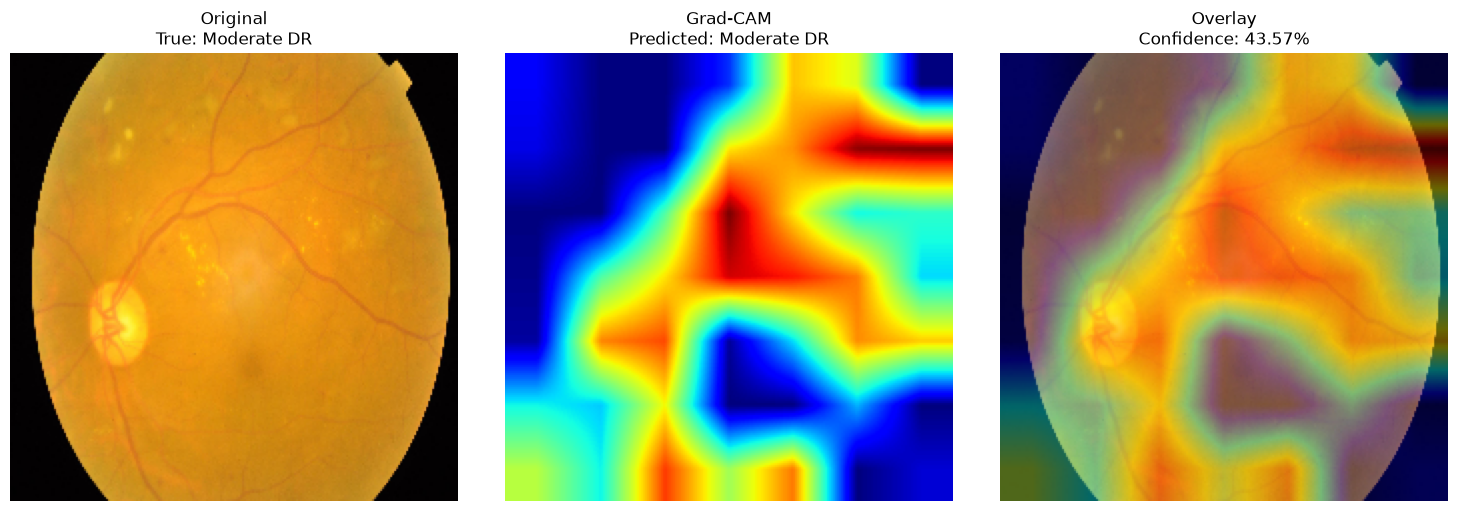

Grad-CAM saved to:
d:\AI-Powered-Diabetic-Retinopathy-System\ml-model\gradcam_outputs\resnet50_gradcam_sample.png


In [27]:
output_dir = "../gradcam_outputs"

os.makedirs(
    output_dir,
    exist_ok=True
)

output_path = os.path.join(
    output_dir,
    "resnet50_gradcam_sample.png"
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title(f"Original\nTrue: {class_names[true_label]}")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title(f"Grad-CAM\nPredicted: {class_names[predicted_class]}")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title(f"Overlay\nConfidence: {confidence * 100:.2f}%")
plt.axis("off")

plt.tight_layout()
plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Grad-CAM saved to:")
print(os.path.abspath(output_path))